Note: you may need to restart the kernel to use updated packages.
                                   Company Ticker     Exchange / Market  \
0                        Grieg Seafood ASA    GSF             Oslo Børs   
1                        Grieg Seafood ASA  GRGSF        US OTC Markets   
2  New Zealand King Salmon Investments Ltd    NZK                   NZX   
3  New Zealand King Salmon Investments Ltd  NZKSF     International OTC   
4                   Sailfish Royalty Corp.   FISH  TSX Venture Exchange   

                           Sector  \
0    Aquaculture / Salmon farming   
1    Aquaculture / Salmon farming   
2       Aquaculture / King salmon   
3       Aquaculture / King salmon   
4  Mining royalties and streaming   

                                Business description  \
0   Norwegian salmon farming and aquaculture company   
1           U.S. OTC quotation for Grieg Seafood ASA   
2      Producer and exporter of king salmon products   
3  International identifier for New 

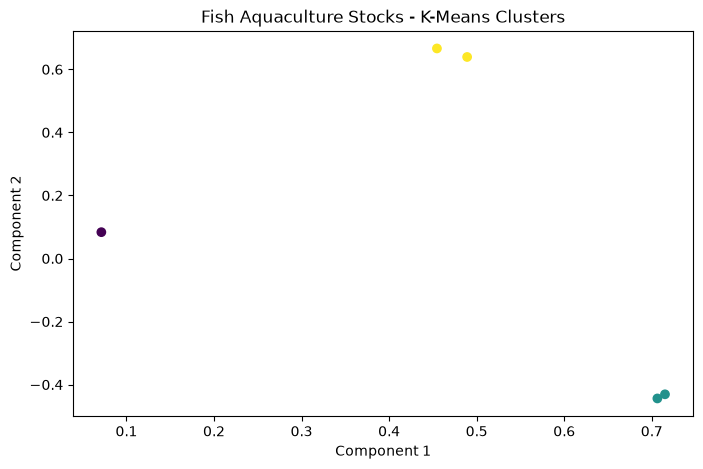

Cluster 0 keywords: ['royalties', 'fish', 'mining royalties', 'streaming', 'mining', 'royalty', 'sailfish royalty', 'million cash', 'exposure mining', 'cash']
Cluster 1 keywords: ['king', 'king salmon', 'salmon', 'nzk', 'new zealand', 'zealand', 'new', 'international', 'zealand king', 'salmon investments']
Cluster 2 keywords: ['usd', 'farming', 'otc', 'seafood asa', 'oslo', 'grieg seafood', 'asa', 'grieg', 'salmon farming', '50']
Completed! Results saved to Fish_Aquaculture_Stocks_Clustered.csv


In [1]:
# 1. Install libraries
%pip install pandas numpy matplotlib scikit-learn scipy

# 2. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import hstack, csr_matrix
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import TruncatedSVD

# 3. Load dataset
df = pd.read_csv("Fish_Aquaculture_Stocks.csv")
df.columns = df.columns.astype(str).str.strip()
df = df.drop_duplicates().dropna(how="all").reset_index(drop=True)

print(df.head())
print(df.info())

# 4. Identify numerical and text columns
num_cols = df.select_dtypes(include=np.number).columns.tolist()
text_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()

# 5. Process numerical data
features = []

if num_cols:
    num = df[num_cols].replace([np.inf, -np.inf], np.nan)
    num = SimpleImputer(strategy="median").fit_transform(num)
    num = StandardScaler().fit_transform(num)
    features.append(csr_matrix(num))

# 6. NLP: Convert text into TF-IDF features
if text_cols:
    text = df[text_cols].fillna("").astype(str).agg(" ".join, axis=1)
    try:
        tfidf = TfidfVectorizer(
            stop_words="english", max_features=1000, ngram_range=(1, 2)
        )
        X_text = tfidf.fit_transform(text)
        features.append(X_text)
    except ValueError:
        pass

# 7. Combine features
if not features:
    raise ValueError("No usable numerical or text columns found.")

X = hstack(features, format="csr") if len(features) > 1 else features[0]

# 8. Find best K using silhouette score
if len(df) < 3:
    raise ValueError("At least 3 rows are needed.")

scores = {}
for k in range(2, min(7, len(df))):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X)
    scores[k] = silhouette_score(
        X, labels,
        sample_size=min(1000, len(df)),
        random_state=42
    )

best_k = max(scores, key=scores.get)
print("Silhouette scores:", scores)
print("Best K:", best_k)

# 9. Apply K-Means
model = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df["Cluster"] = model.fit_predict(X)

print(df.groupby("Cluster").size())

# 10. Visualize clusters
if X.shape[1] >= 2:
    reduced = TruncatedSVD(n_components=2, random_state=42).fit_transform(X)
    plt.figure(figsize=(8, 5))
    plt.scatter(reduced[:, 0], reduced[:, 1],
                c=df["Cluster"], cmap="viridis")
    plt.title("Fish Aquaculture Stocks - K-Means Clusters")
    plt.xlabel("Component 1")
    plt.ylabel("Component 2")
    plt.show()

# 11. Display NLP keywords
if text_cols and "tfidf" in globals():
    terms = tfidf.get_feature_names_out()
    for c in sorted(df["Cluster"].unique()):
        idx = np.where(df["Cluster"].values == c)[0]
        avg = np.asarray(X_text[idx].mean(axis=0)).ravel()
        print(f"Cluster {c} keywords:",
              [terms[i] for i in avg.argsort()[-10:][::-1] if avg[i] > 0])

# 12. Save results
df.to_csv("Fish_Aquaculture_Stocks_Clustered.csv", index=False)
print("Completed! Results saved to Fish_Aquaculture_Stocks_Clustered.csv")